# Task 1.3(b, c): prepare one logical state

Inflation from vacuum prepares a superposition of both codewords. **To initialize $\lvert0_L\rangle\equiv\lvert+\alpha\rangle$, we first displace the memory toward positive amplitude, then stabilize it.** The displacement selects the sign; stabilization restores the target amplitude.

A resonant memory drive with Hamiltonian $i\varepsilon_1(t)(a^\dagger-a)$ produces displacement along the real axis containing the codewords $\lvert\pm\alpha\rangle$. Here $\varepsilon_1$ is the real drive amplitude in µs⁻¹. Rotating the drive phase by 90° gives the Hamiltonian $\varepsilon_1(t)(a+a^\dagger)$ and displacement along the perpendicular imaginary axis. This orthogonal drive provides a control for the phase dependence of codeword selection.

An ideal real-axis pulse applied before stabilization prepares $\lvert\beta\rangle$, where $\beta=\int_{\mathrm{pulse}}\varepsilon_1(t)\mathrm{d}t$. This dimensionless amplitude gives initial mean photon number $\lvert\beta\rvert^2$; $\alpha=2.1$ is the target amplitude.

1. Start from vacuum with two-photon stabilization disabled.
2. Apply this memory pulse with area $\beta=1.5$ along the positive real axis to prepare $\lvert\beta=1.5\rangle_a\lvert0\rangle_b$.
3. Turn off that pulse and enable the two-photon exchange pump and buffer drive. Keep stabilization on to bring the memory toward $\lvert+\alpha\rangle$.

Using $\beta=1.5\lt\alpha=2.1$ tests amplitude correction: fidelity rises from 69.77% initially to 99.878% at 2 µs, remaining above 99% from 0.41 µs onward through 2 µs. For this calculation, we initialize the memory directly in $\lvert\beta=1.5\rangle$ and simulate the subsequent stabilization. The preparation pulse itself is idealized; reported times start when stabilization is enabled.

For comparison, we start from vacuum and apply the real-axis drive during the first 0.1 µs while stabilization is active, simulating the pulse and stabilization together. Applying the orthogonal drive over the same interval gives zero mean real amplitude and approximately 50% target fidelity.

We report fidelity $F_\alpha$ with $\lvert+\alpha\rangle$ and normalized mean amplitude $\mathrm{Re}\langle a\rangle/\alpha$ (near +1 for the desired state, zero for a symmetric occupation of the two signs).

The notebook loads saved results by default. Set `RERUN=True` to recompute the amplitude and phase sweeps and the driven examples.


In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
RERUN = False
if RERUN:
    from src import config as C
    from tasks import task_1_3b
    with redirect_stdout(io.StringIO()):
        task_1_3b.main(C.NA, C.NB)
r = load('task_1_3b')

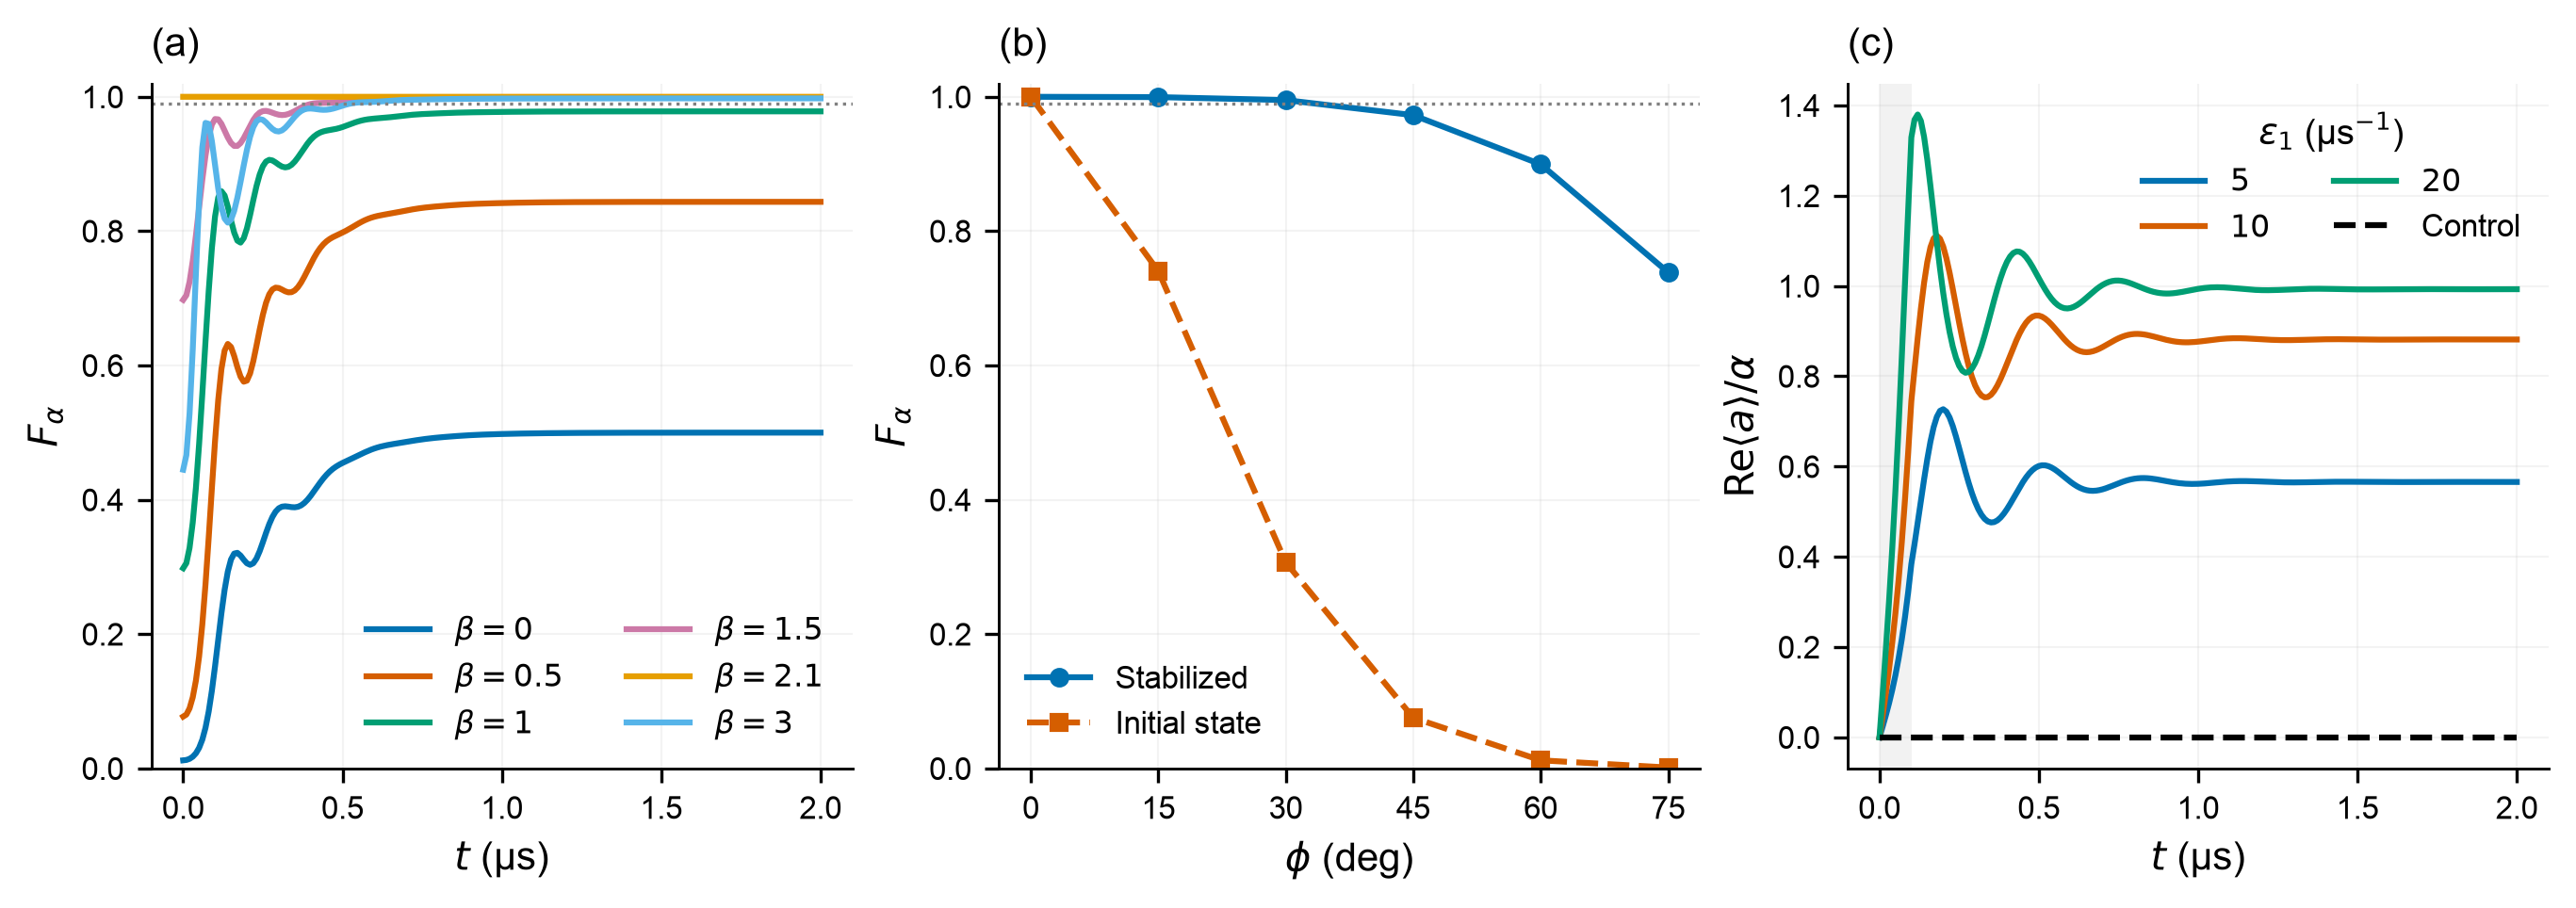

In [3]:
show('task_1_3b_logical_prep', 1150)

**Preparation of a selected coherent state.** Fidelity is $F_\alpha=\langle\alpha\rvert\rho_a\lvert\alpha\rangle$. (a) Evolution from $|\beta\rangle_a|0\rangle_b$ for real initial coherent-state amplitude $\beta$. (b) Fidelity at $t=2$ µs after stabilization, compared with the initial overlap $\lvert\langle\alpha\vert\beta\rangle\rvert^2$, for $\beta=\alpha e^{i\phi}$, where $\phi$ is the initial phase error relative to the target. Dotted guides mark $F_\alpha=0.99$. (c) Normalized memory amplitude with a drive $i\varepsilon_1(a^\dagger-a)$ applied over the shaded interval, 0–0.1 µs. The control uses $10(a+a^\dagger)$ in the same interval. $\varepsilon_1$ denotes the memory-drive amplitude in µs⁻¹. For displaced starts, time begins after the idealized pulse. All simulations use $(N_a,N_b)=(32,12)$ and $\alpha=2.1$.

### Wigner evolution


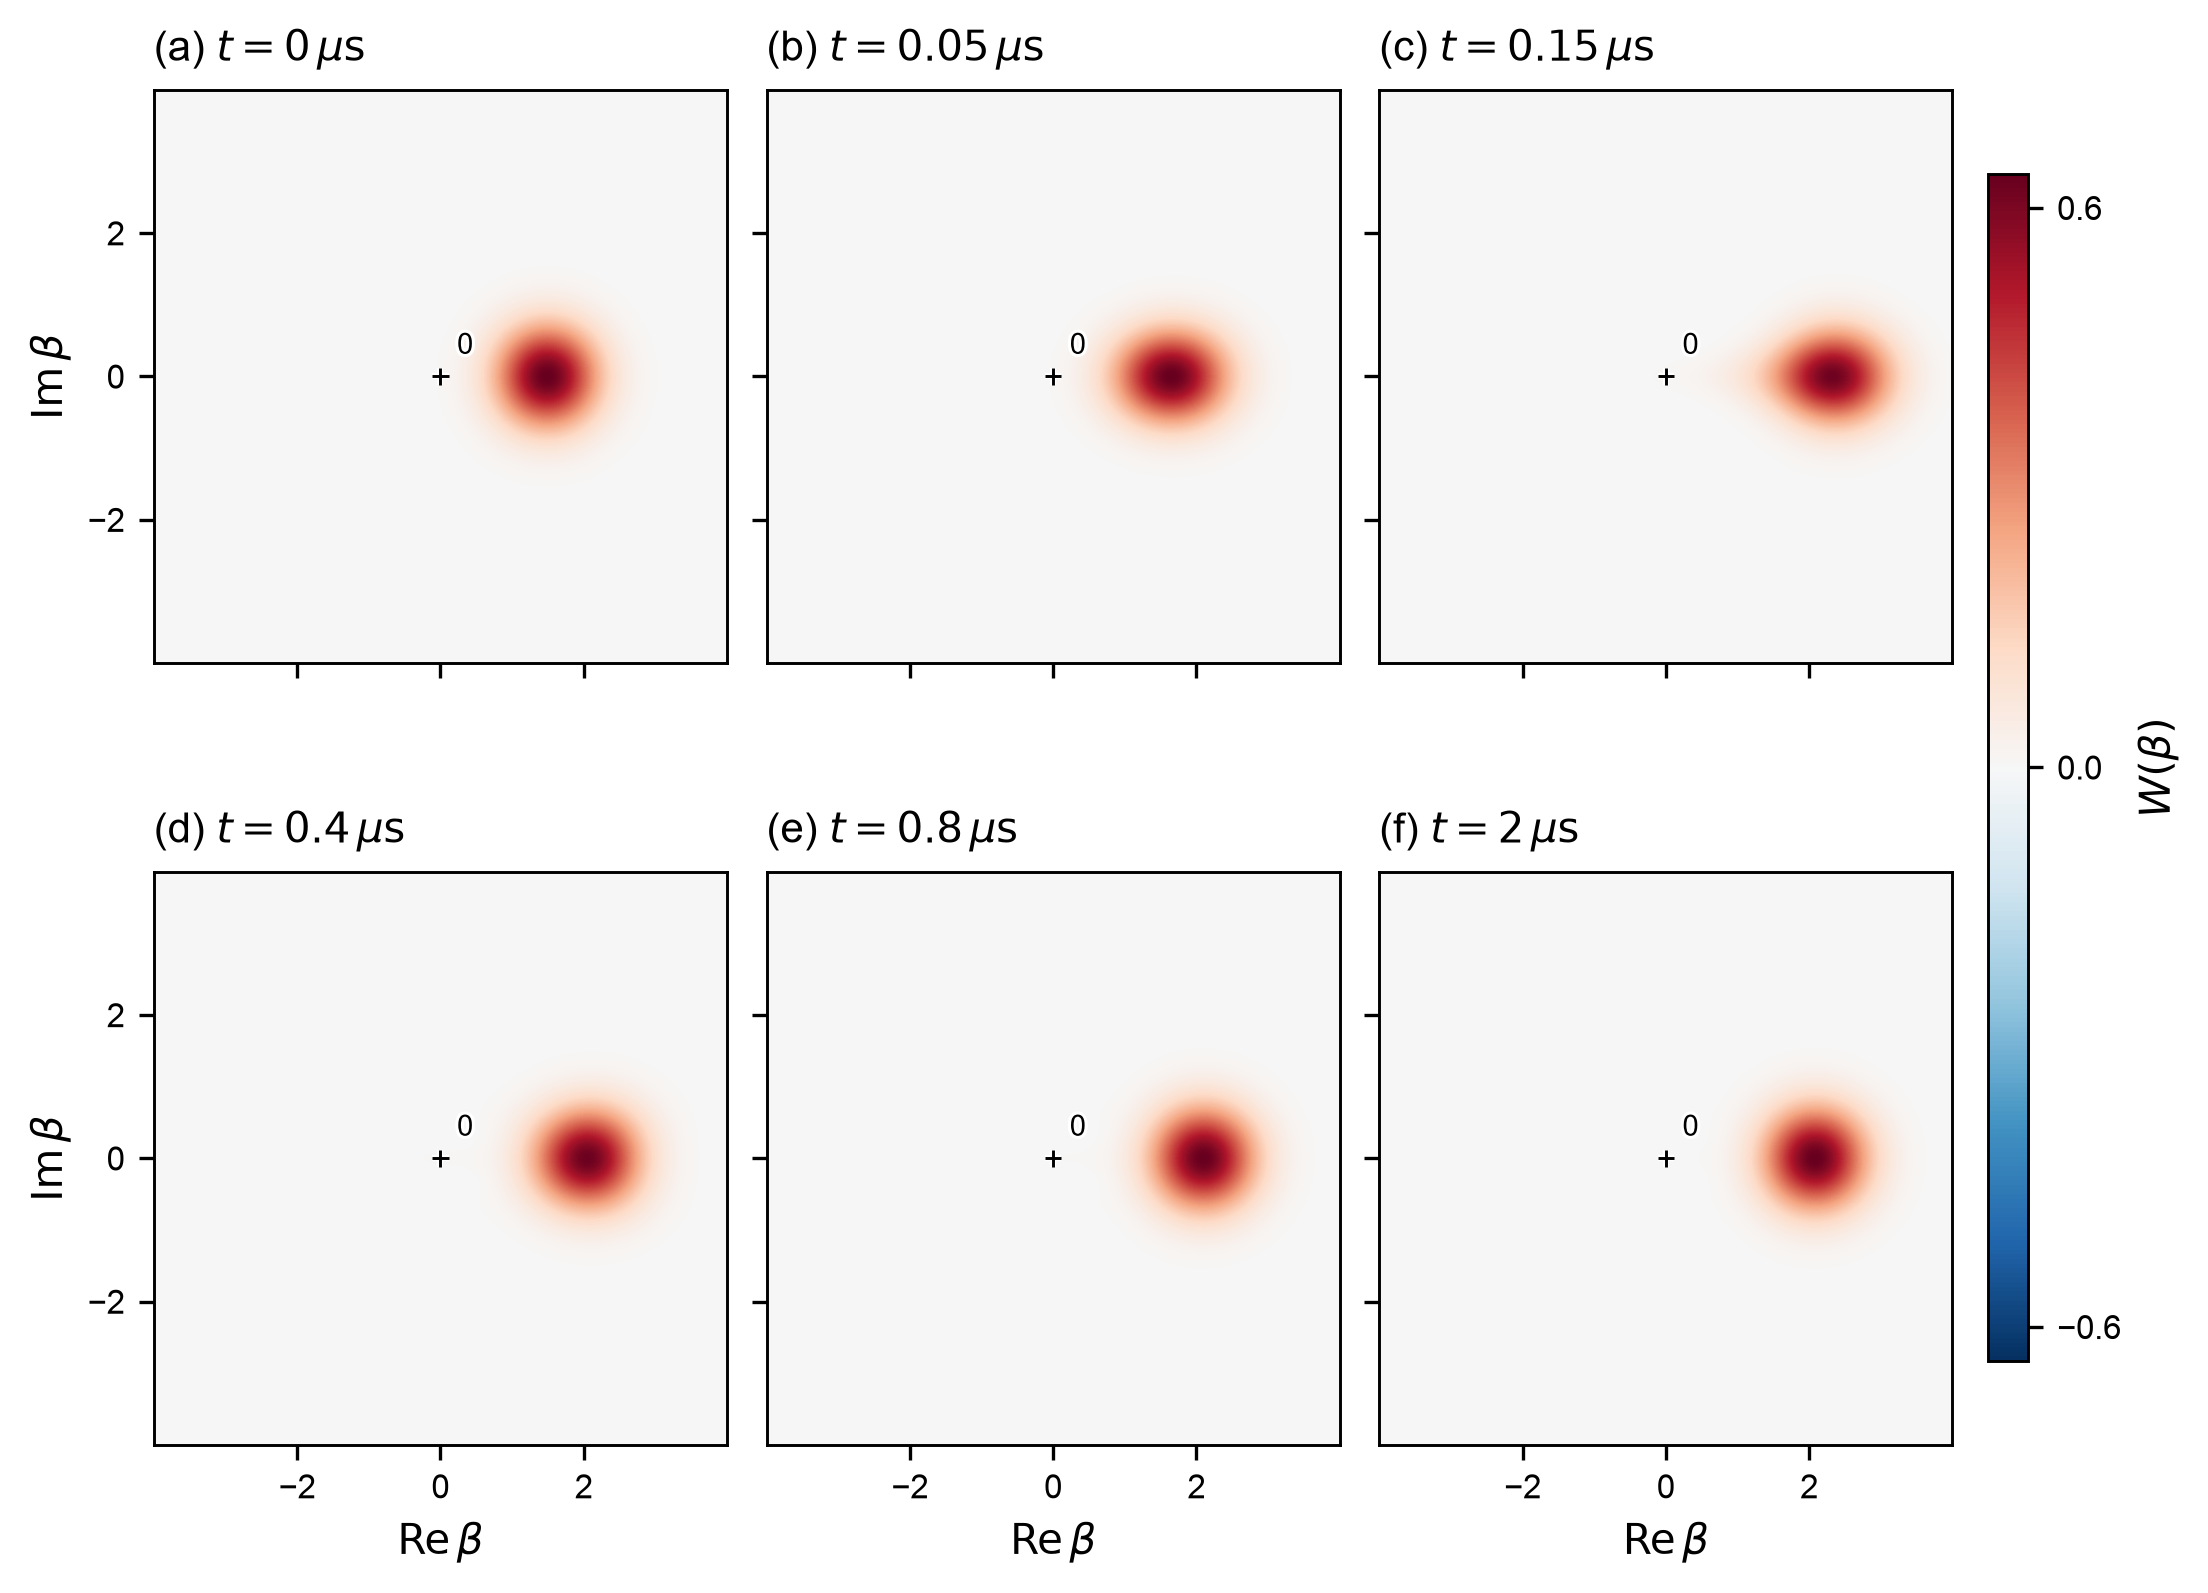

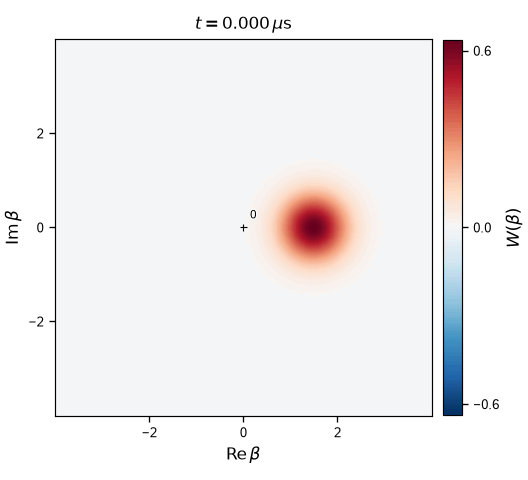

In [4]:
show('task_1_3b_wigner', 1000)
display(Image(filename=str(ROOT / 'figures/task_1_3b_wigner.gif'), width=530))


**Stabilization after displacement.** Reduced-memory Wigner functions for the proposed preparation sequence, initialized in $\lvert\beta=1.5\rangle_a\lvert0\rangle_b$ and stabilized toward $\lvert+\alpha\rangle$ at $\alpha=2.1$, $(N_a,N_b)=(32,12)$, including memory single-photon loss. Time begins after the idealized displacement pulse, when two-photon stabilization is enabled; the pulse itself is not simulated. Static panels show the indicated times; the animation uses all 201 reduced-memory states over 0–2 µs at 10-ns spacing. Axes denote the complex phase-space coordinate $\beta$. The fixed color range is $-2/\pi\leq W\leq2/\pi$ in every panel and frame.

## 1.3(c): what does preparation cost?

- **Hardware:** preparation requires a resonant memory drive and phase synchronization with the stabilization pump. A suitable existing memory-drive line can be reused; otherwise an additional line is required.
- **Calibration:** stabilization relaxes the requirement to prepare the target amplitude exactly, but the pulse must provide sufficient bias toward the desired codeword. The tested real amplitudes $\beta=1.5,2.1,3.0$ all give fidelity above 99% at 2 µs. Phase accuracy remains important: at $\lvert\beta\rvert=\alpha=2.1$, a 30° phase error gives **99.51%** final fidelity, compared with **30.68%** initially; a 45° error gives 97.27% final fidelity.
- **Time:** for $\beta=1.5$, preparation takes the displacement-pulse duration plus **0.41 µs of stabilization** to reach 99% fidelity. The pulse is idealized as an initial coherent state, so its duration and errors during the pulse are not included in this simulation.
- **Interaction with stabilization:** the proposed sequence ends the memory pulse before stabilization begins. Applying the drive during inflation changes the transient: the tested $\varepsilon_1=20$ µs⁻¹ pulse raises the sampled memory peak to **8.51 photons**, compared with 6.89 from vacuum without a memory drive.

See [TECHNICAL.md](../TECHNICAL.md) for the numerical evidence.


## Numerical summaries

In [5]:
import pandas as pd
cols = ['label', 'F_plus_alpha_2us', 're_a_over_alpha_2us', 't_F_099_us', 'bare_overlap', 'peak_na', 'max_top2_a', 'max_top_b']
for k in ('A1_amplitude', 'A2_phase', 'B_drive'):
    display(pd.DataFrame(r[k]).reindex(columns=cols).round(4))
r['control_wrong_quadrature']

,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,beta=0.0,0.5000,0.0000,inf,0.0122,6.8944,0.0,0.0002
1,beta=0.5,0.8436,0.6867,inf,0.0773,6.5598,0.0,0.0001
2,beta=1.0,0.9783,0.9559,inf,0.2982,6.2261,0.0,0.0000
3,beta=1.5,0.9988,0.9968,0.41,0.6977,5.5265,0.0,0.0000
4,beta=2.1,1.0000,0.9992,0.00,1.0000,4.4100,0.0,0.0000
5,beta=3.0,0.9977,0.9946,0.53,0.4449,9.0000,0.0,0.0000


,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,phase=0deg,1.0000,0.9992,0.00,1.0000,4.4100,0.0,0.0000
1,phase=15deg,0.9995,0.9983,0.37,0.7404,4.7389,0.0,0.0000
2,phase=30deg,0.9951,0.9894,0.67,0.3068,5.6016,0.0,0.0000
3,phase=45deg,0.9727,0.9446,inf,0.0755,6.5725,0.0,0.0000
4,phase=60deg,0.8994,0.7983,inf,0.0122,7.3075,0.0,0.0002
5,phase=75deg,0.7386,0.4768,inf,0.0014,7.9285,0.0,0.0005


,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,eps1=5.0,0.7832,0.5658,inf,NaN,6.6566,0.0,0.0001
1,eps1=10.0,0.9411,0.8815,inf,NaN,6.5856,0.0,0.0000
2,eps1=20.0,0.9968,0.9929,0.67,NaN,8.5135,0.0,0.0000


{'label': 'eps*(a+a^dag), eps=10',
 'F_plus_alpha_2us': 0.49999368271180095,
 're_a_over_alpha_2us': 0.0,
 't_F_099_us': inf,
 'peak_na': 7.207165433681015,
 'max_top2_a': 1.7328312405091482e-05,
 'max_top_b': 0.00022187639379422767}